# Particle filter: try it

Edit the settings in a cell and re-run it. **1** picks a place on the Tellus map, **2** flies a
simulated drone there and runs the filter, and **3** runs the same filter on your own data.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
from ins import Trajectory
from navfilter import scenario

## 1. Pick a place

Any latitude/longitude the national Tellus grid covers. The star marks the point. The left panel
is the whole map, the right is the field around the point. **The more the field varies there,
the better the fix**, and a flat area gives the filter nothing to match.

54.0800, -9.0200: 36.3 nT
   field varies by 52.0 nT (std) within 3 km


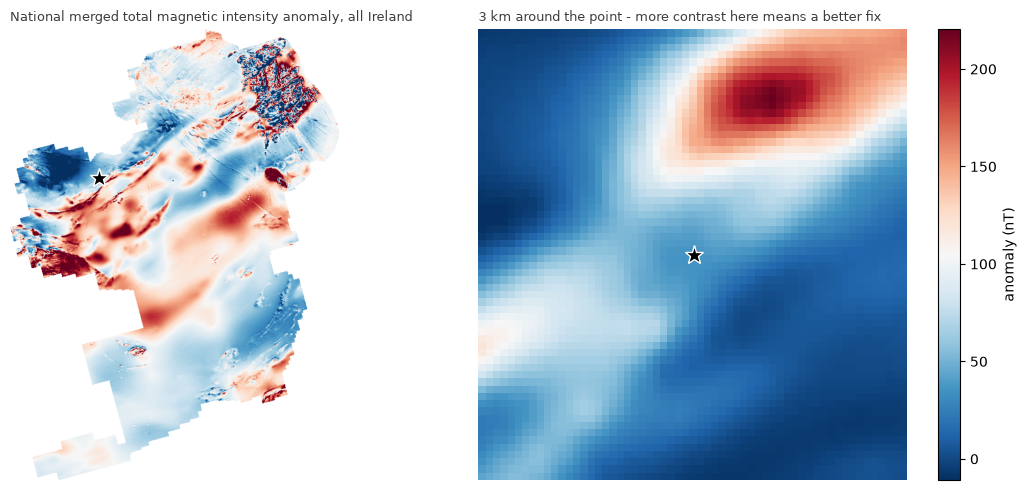

In [2]:
LAT, LON = 54.08, -9.02        # south-west corner of the flight (Co. Mayo: lots of texture)
# LAT, LON = 53.10, -7.90      # the midlands: nearly flat, watch the filter struggle

scenario.show_location(LAT, LON);

## 2. Fly it

A lawnmower survey starting at that point, with GNSS cut at take-off. Each IMU grade gets its own
INS run (dashed line) and the filter's corrected track (solid line). Grades: `consumer_mems` (the
Pixhawk's chip), `tactical`, `navigation`, `perfect`.

consumer_mems, 10.1 min after the cut
            INS only  INS+MagNav  PF 2sigma
    1 min      173.3       127.0      499.0  m
    5 min    11551.0      1197.5     1248.0  m
   10 min    46018.2      2526.0     3906.6  m
   20 min       -           -          -     m

tactical, 10.1 min after the cut
            INS only  INS+MagNav  PF 2sigma
    1 min        2.9         7.4       78.7  m
    5 min       66.6         7.9      166.6  m
   10 min      227.3        42.9      226.8  m
   20 min       -           -          -     m



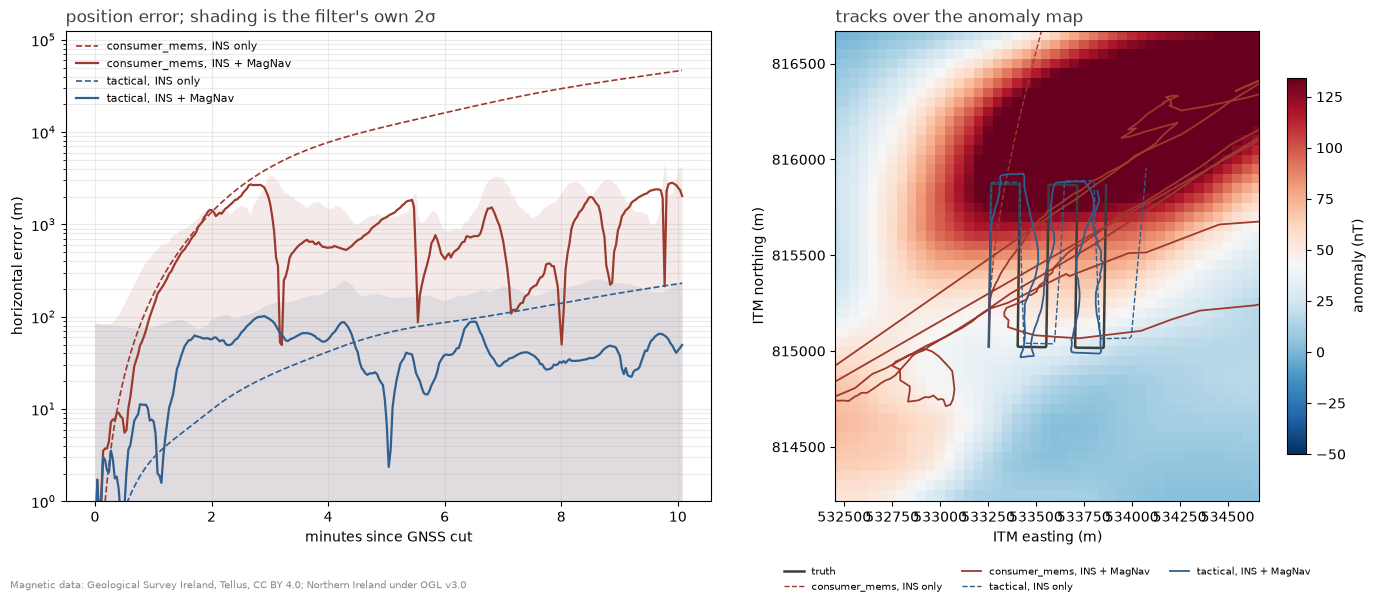

In [3]:
sim = scenario.simulate(
    LAT, LON,
    minutes=10,                          # 20 min takes about 45 s
    grades=["consumer_mems", "tactical"],
    particles=2000,
    cold_start=False,                    # True: start 500 m unsure instead of 30 m
    seed=0,                              # change for a different random flight
)
sim.summary()
scenario.plot(sim.runs, sim.filter_map, sim.truth);

## 3. Your own data

The filter needs one table, with a row per magnetometer reading:

| column | what it is |
|---|---|
| `t_s` | seconds, one clock for everything |
| `lat`, `lon`, `alt_m` | where the **INS thinks** the drone is, with GNSS ignored |
| `field_nt` | total field from the OPM, ~49,000 nT in Ireland (empty for a dropped reading) |
| `true_lat`, `true_lon` | *optional*: the GNSS position, only used to score the result |

The first row is treated as the moment GNSS was lost. The cell below writes the flight from
step 2 in exactly this format, so you can see what a file should look like. To use real data,
point `CSV` at your own file instead.

Real data has two catches. The diurnal variation is **not** corrected yet, and that's roughly 10–20 nT
of slow drift on a real day. And the flight has to be over Ireland, because that's what the map
covers.

In [4]:
run = sim.runs["tactical"]
t = np.arange(run.ins_track.t[0] + 0.5, run.ins_track.t[-1], 0.1)        # 10 Hz
ins, truth = run.ins_track.at(t), sim.truth.at(t)
from sensor import FieldModel, NoDiurnal
true_field = FieldModel(grid=sim.filter_map, diurnal=NoDiurnal()).at(truth).total_nt

pd.DataFrame(dict(t_s=t, lat=ins.lat, lon=ins.lon, alt_m=ins.alt_m,
                  field_nt=true_field + np.random.default_rng(0).normal(0, 1, len(t)),
                  true_lat=truth.lat, true_lon=truth.lon)
             ).to_csv("../outputs/example_flight.csv", index=False)
pd.read_csv("../outputs/example_flight.csv").head()

,t_s,lat,lon,alt_m,field_nt,true_lat,true_lon
0,0.5,54.080036,-9.02,60.005424,49702.405856,54.080036,-9.02
1,0.6,54.080043,-9.02,60.004304,49702.176893,54.080043,-9.02
2,0.7,54.080050,-9.02,60.003183,49702.978294,54.080050,-9.02
3,0.8,54.080058,-9.02,60.002062,49702.471648,54.080057,-9.02
4,0.9,54.080065,-9.02,60.000941,49701.859958,54.080065,-9.02


log, 10.0 min after the cut
            INS only  INS+MagNav  PF 2sigma
    1 min        3.0        12.5       77.9  m
    5 min       66.8        15.6      216.2  m
   10 min      227.7       133.0      223.4  m
   20 min       -           -          -     m


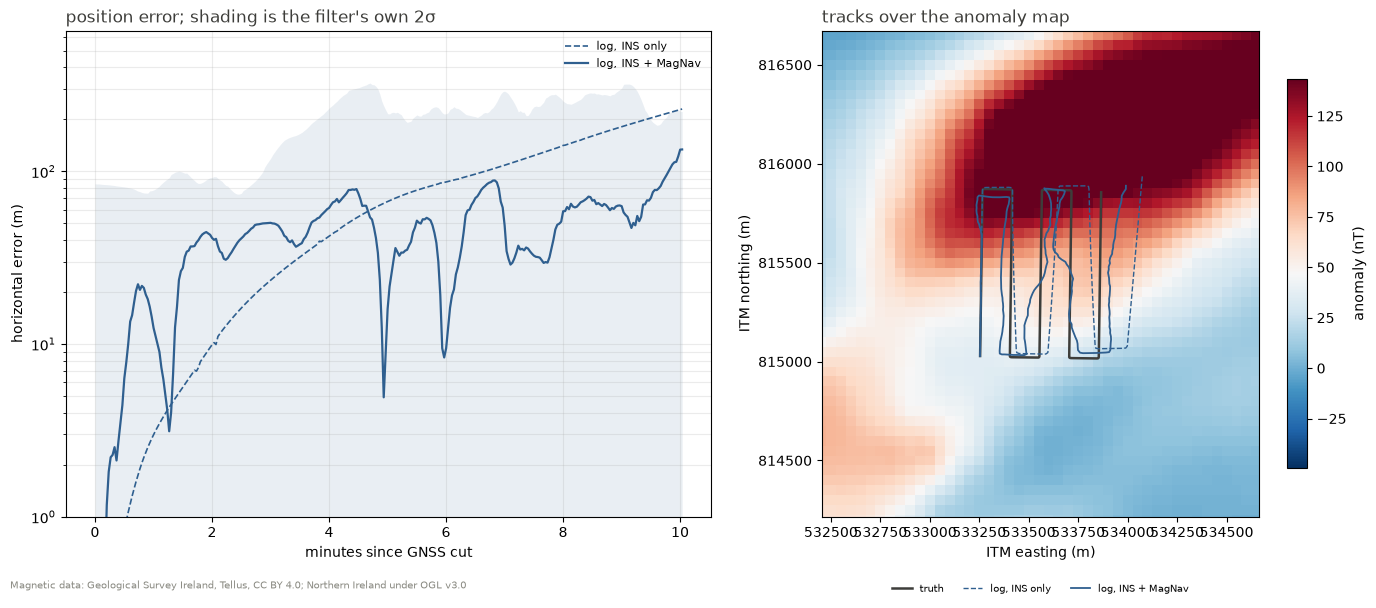

In [5]:
CSV = "../outputs/example_flight.csv"     # <- your file here
GRADE = "tactical"                         # which IMU made the lat/lon columns

df = pd.read_csv(CSV)
ins = Trajectory(df.t_s, df.lat, df.lon, df.alt_m)
truth = (Trajectory(df.t_s, df.true_lat, df.true_lon, df.alt_m)
         if "true_lat" in df else None)

result = scenario.filter_log(ins, df.t_s, df.field_nt, grade=GRADE, truth=truth)
result.summary()
scenario.plot({"log": result}, scenario.load_map().subset(
    (df.lon.min() - 0.05, df.lat.min() - 0.05, df.lon.max() + 0.05, df.lat.max() + 0.05)),
    truth);